# 02 · Model comparison (5-fold cross-validation by person)

| group | models |
|---|---|
| classical baselines | logistic regression, random forest, XGBoost (on the 46-number summary row + tempo) |
| neural models (attention pooling → α) | 1D-CNN, BiLSTM, BiGRU, CNN-LSTM, TCN, ST-Transformer |

Every neural model ends with **attention pooling over the 64 frames**: its weights α say which moments decided the class.
The final product uses α to light up the error region on the 3D body at the right time, so α is checked too.

**Evaluation protocol (identical for every model and every variant).**
* **5-fold cross-validation grouped by person** (StratifiedGroupKFold, k = 5): each fold tests 3-4 people the model has
  never seen; every person is tested once per seed.
* **3 seeds** (0, 1, 2): 15 runs per model; the reported number is the mean ± standard deviation over the 15 runs.
* **Validation persons**: inside each fold, 2 training persons choose the best epoch;
  the test persons are never used for any choice.
* **Early stopping**: training stops when the validation macro-F1 has not improved for **20 epochs** (at most 60 epochs);
  the weights of the best epoch are kept and saved as a checkpoint (`<model>/fold_<seed>_<k>/best.pt`, with the best epoch,
  its validation F1, the number of epochs run, the normalisation statistics and the test metrics).
* **Normalisation** statistics from the training part of each fold only; **loss weights** balance the classes and let
  every recording count equally.
* **Metrics**: macro-F1 per rep (main), accuracy, macro-F1 per recording (mean probability over its reps), per-class F1,
  confusion matrix; **paired Wilcoxon test** on the 15 identical runs when two models or variants are compared.

**How to run.** Run All after notebook 01. About 1 hour on the laptop RTX 3050 (the ST-Transformer takes ~50 min of it).
The monitor cell shows progress and ETA; interrupting it does not stop the training.

**Outputs.** `results/02_model_comparison/` (comparison tables, figures, one report per model, `best_model.json`).

In [1]:
# ---- setup (every notebook starts with this cell) ----
import sys, json, time, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()     # research_folders/
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown, clear_output, Image
pd.set_option("display.precision", 3); pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 120)
from squat_research.common import load_config, apply_overrides, results_dir, nice, read_json, write_json
from squat_research.dataset import build_dataset, load_dataset
from squat_research.engine import comparison_table, select_best, fold_scores, paired_test
from squat_research import viz, monitor
cfg = load_config()
print("research folder:", ROOT)
from squat_research.models import MODEL_INFO, build_model, n_params, TREE_MODELS
from squat_research.report import model_report
OUT = results_dir(cfg, "02_model_comparison"); FIG = results_dir(cfg, "02_model_comparison", "figures")
REP = results_dir(cfg, "02_model_comparison", "model_reports"); RUN = OUT / "cv"
ds = load_dataset(cfg); C = ds["classes"]
MODELS = cfg["baseline_models"] + cfg["neural_models"]

research folder: C:\Users\dynam\Desktop\Project1\research_folders


## 1. The models: what each receives and how it processes it

In [2]:
T, J, F = ds["joints"].shape[1], ds["joints"].shape[2], ds["frame"].shape[2]
models_tab = pd.DataFrame([{"model": nice(m), "family": MODEL_INFO[m]["family"], "input": MODEL_INFO[m]["input"],
                            "processing": MODEL_INFO[m]["processing"],
                            "parameters": "-" if m in TREE_MODELS else f"{n_params(build_model(m, J, F, T, len(C), ds['meta']['joint_names'], cfg['model'])):,}"}
                           for m in MODELS])
models_tab.to_csv(OUT / "models_overview.csv", index=False); display(models_tab)

,model,family,input,processing,parameters
0,Logistic regression,classical baseline,summary row: 46 statistics per rep from rep_features.csv (min / max / at-bottom of each pipeline angle) + 4 tempo nu...,"median imputation of missing values, z-score, multinomial logistic regression (L2, C = 1); sample weights: every rec...",-
1,Random forest,classical baseline,summary row (46) + tempo (4) = 50 values per rep,"median imputation, 300 decision trees (bootstrap), majority of tree probabilities",-
2,XGBoost,classical baseline,summary row (46) + tempo (4) = 50 values per rep,"median imputation, 300 gradient-boosted trees, depth 4, learning rate 0.1, row / column subsampling 0.9",-
3,1D-CNN,convolutional,"per frame: 22 joints x 6 (position + velocity, body frame) + 19 frame features = 151 channels, 64 frames","3 Conv1d layers (kernel 5; 64 -> 128 -> 128 channels; BatchNorm, GELU, dropout): each output sees 13 frames; attenti...","206,598"
4,BiLSTM,recurrent,"per frame: 151 channels (as 1D-CNN), 64 frames","linear projection to 64, 2-layer bidirectional LSTM (64 per direction): every frame summarises the whole rep in both...","210,054"
5,BiGRU,recurrent,"per frame: 151 channels, 64 frames","linear projection to 64, 2-layer bidirectional GRU (64 per direction); attention pooling -> alpha; + tempo -> classi...","168,582"
6,CNN-LSTM,hybrid,"per frame: 151 channels, 64 frames","3 Conv1d blocks (kernel 5, 64 channels, LayerNorm, residual) extract local movement, then a 2-layer bidirectional LS...","155,398"
7,TCN,convolutional,"per frame: 151 channels, 64 frames","input projection to 64 channels, 4 residual blocks of two dilated Conv1d (kernel 3, dilation 1, 2, 4, 8; non-causal)...","118,598"
8,ST-Transformer,attention,"per frame: 22 joint tokens (6 values each) + 1 frame token (19 features) = 23 tokens, 64 frames",tokens embedded to 64 + learned joint and time tags; 4 blocks of [spatial self-attention over the 23 tokens of a fra...,"289,670"


## 2. Train all models (background process + live monitor)

In [3]:
if not (RUN / "progress.json").exists() or read_json(RUN / "progress.json")["state"] != "done":
    proc = monitor.launch(MODELS, RUN, save_models=True)     # checkpoints: <model>/fold_<seed>_<k>/best.pt (best epoch)
monitor.watch(RUN, every=30)      # interrupt to stop watching; the training continues (monitor.stop(RUN) stops it)

state: running   folds 134/135   elapsed 1 h 03 min   ETA 3 min 47 s   updated 2026-10-18 00:05:10
now: ST-Transformer  seed 2  fold 4  epoch 26/60  train loss 0.246  val F1 0.760  best epoch 6

              model  folds done  macro-F1 so far   std
              BiGRU          15            0.717 0.104
             BiLSTM          15            0.693 0.081
             1D-CNN          15            0.747 0.092
           CNN-LSTM          15            0.758 0.112
Logistic regression          15            0.460 0.080
      Random forest          15            0.508 0.054
     ST-Transformer          14            0.682 0.098
                TCN          15            0.734 0.126
            XGBoost          15            0.527 0.055

[23:38:37]   ST-Transformer seed 1 fold 3: macro-F1 0.822 acc 0.845 persons ['D', 'G', 'O', 'P'] best epoch 19
[23:43:09]   ST-Transformer seed 1 fold 4: macro-F1 0.607 acc 0.610 persons ['A', 'C', 'N'] best epoch 6
[23:49:54]   ST-Transformer seed 2 fol

## 3. Results

In [4]:
table = comparison_table(RUN)
table["group"] = ["classical baseline" if m in TREE_MODELS else "neural" for m in table["model"]]
table.to_csv(OUT / "comparison.csv", index=False)
(OUT / "comparison.md").write_text(table.to_markdown(index=False, floatfmt=".3f"), encoding="utf-8")
display(table[["name", "group", "macro_f1", "macro_f1_std", "accuracy", "rec_macro_f1", "alpha_drop", "random_drop", "params", "median_best_epoch", "minutes"]])

,name,group,macro_f1,macro_f1_std,accuracy,rec_macro_f1,alpha_drop,random_drop,params,median_best_epoch,minutes
0,CNN-LSTM,neural,0.758,0.108,0.775,0.777,0.023,3.591e-03,155398.0,13.0,1.5
1,1D-CNN,neural,0.747,0.089,0.762,0.763,0.054,6.497e-03,206598.0,10.0,1.1
2,TCN,neural,0.734,0.122,0.750,0.744,0.050,8.308e-03,118598.0,10.0,1.5
3,BiGRU,neural,0.717,0.100,0.738,0.754,0.031,1.326e-03,168582.0,14.0,1.2
4,BiLSTM,neural,0.693,0.078,0.713,0.737,0.007,-6.431e-04,210054.0,15.0,1.3
5,ST-Transformer,neural,0.677,0.093,0.706,0.689,0.011,3.422e-03,289670.0,6.0,56.4
6,XGBoost,classical baseline,0.527,0.053,0.546,0.564,NaN,NaN,NaN,NaN,0.4
7,Random forest,classical baseline,0.508,0.052,0.529,0.517,NaN,NaN,NaN,NaN,0.2
8,Logistic regression,classical baseline,0.460,0.078,0.478,0.470,NaN,NaN,NaN,NaN,0.0


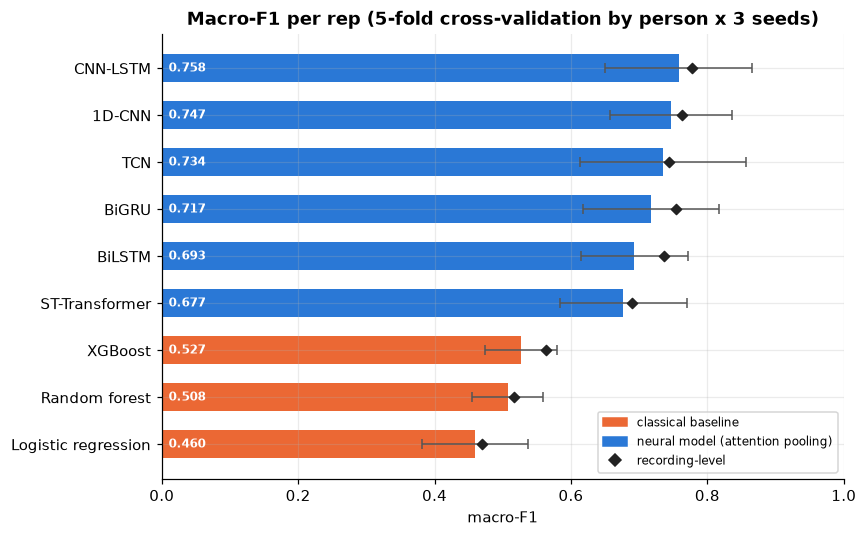

In [5]:
viz.comparison(table, FIG, title="Macro-F1 per rep (5-fold cross-validation by person x 3 seeds)"); plt.show()

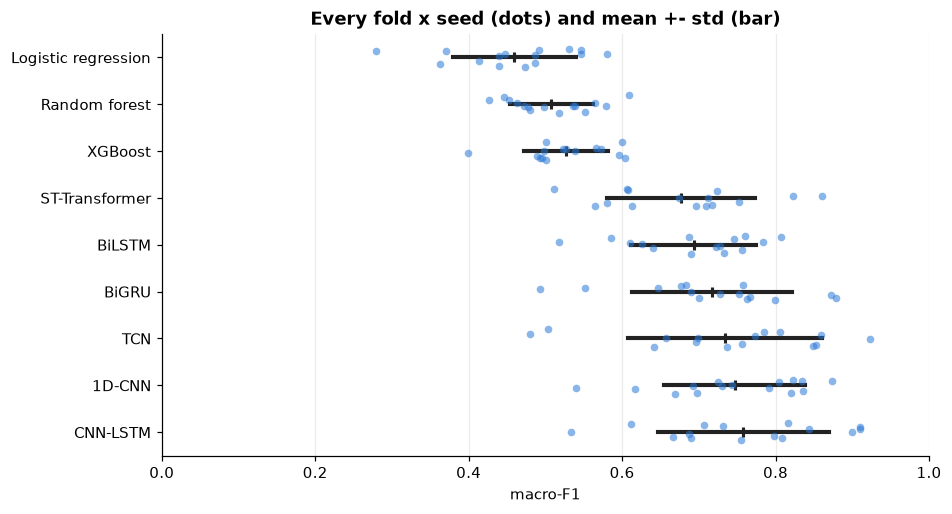

In [6]:
viz.fold_spread(RUN, list(table["model"]), FIG); plt.show()

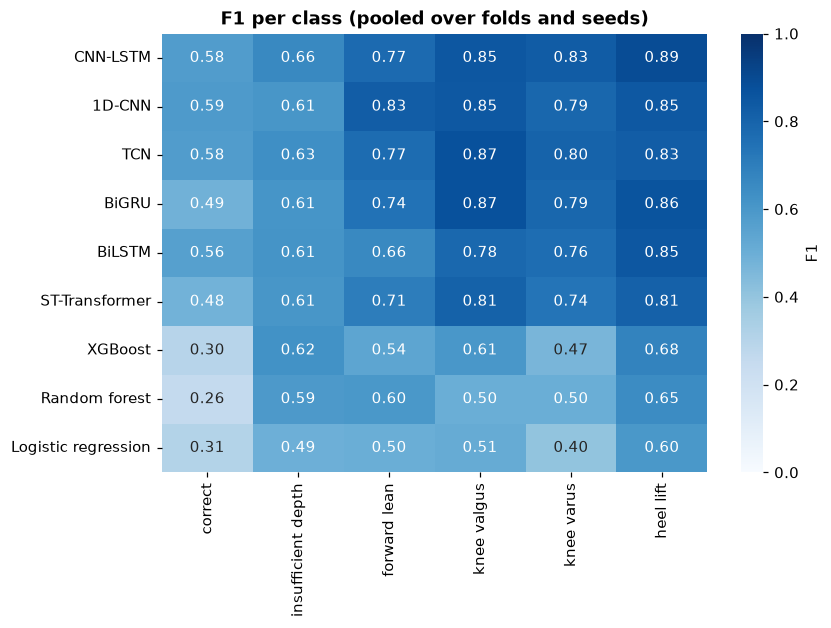

In [7]:
viz.per_class(RUN, list(table["model"]), C, FIG); plt.show()

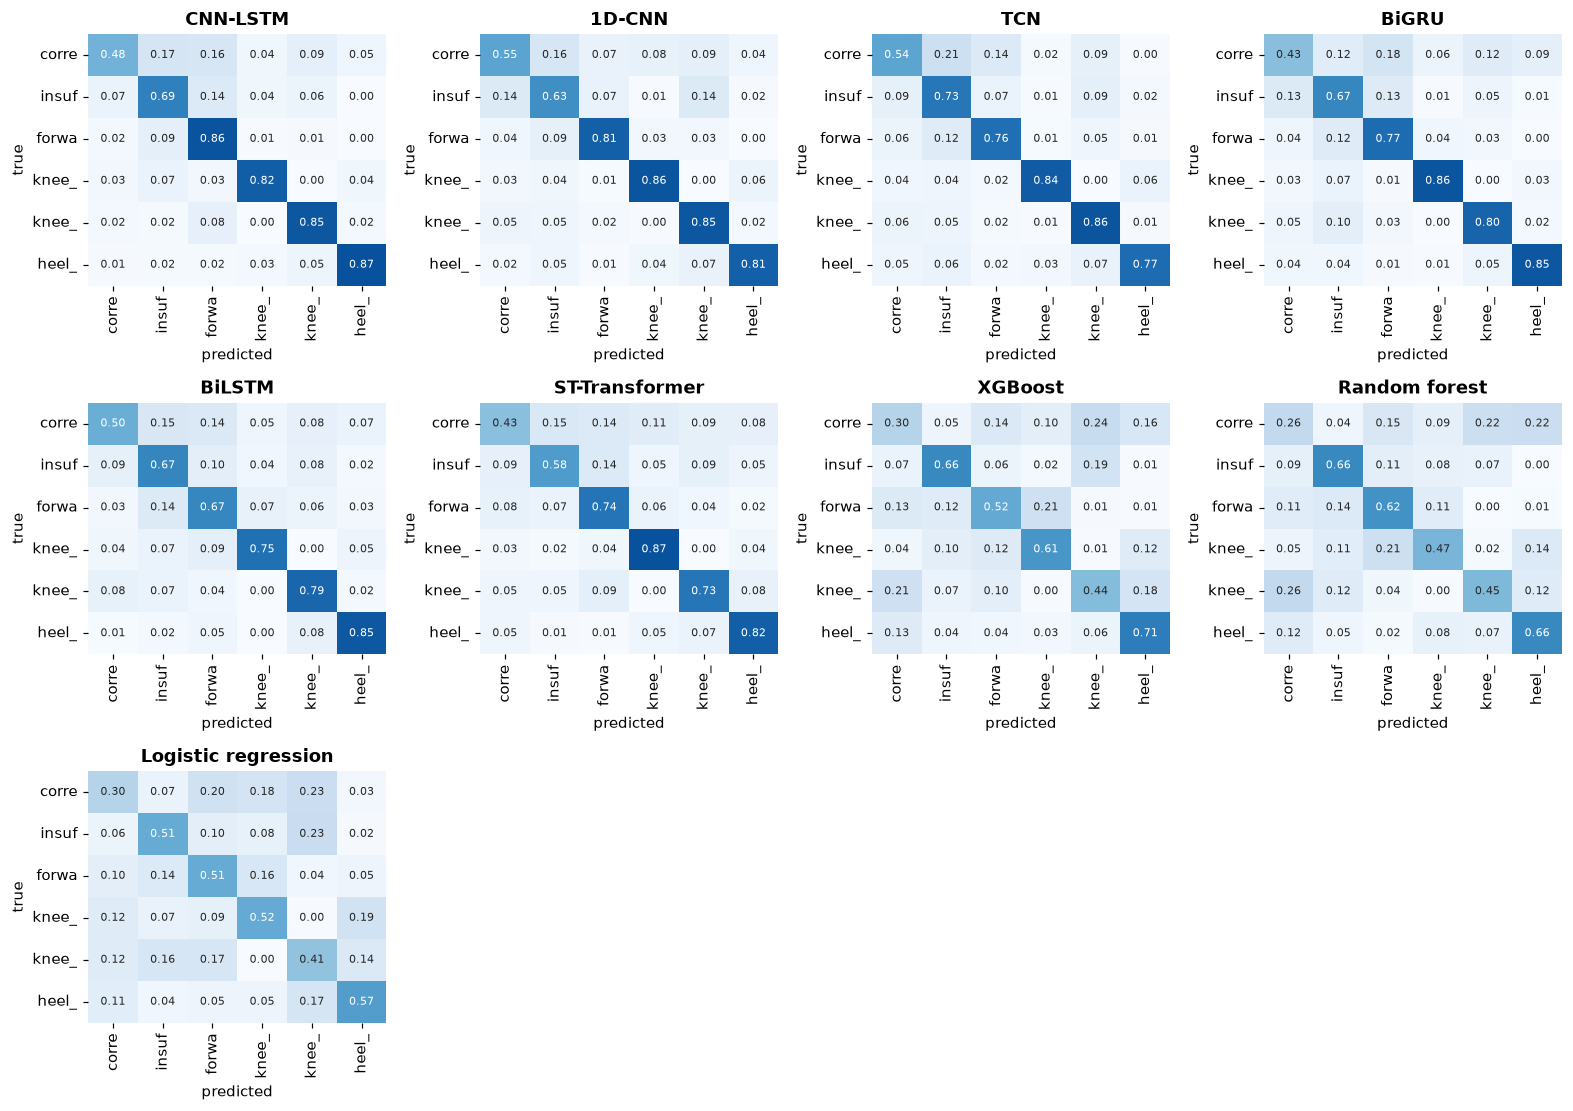

In [8]:
viz.confusions(RUN, list(table["model"]), C, FIG); plt.show()

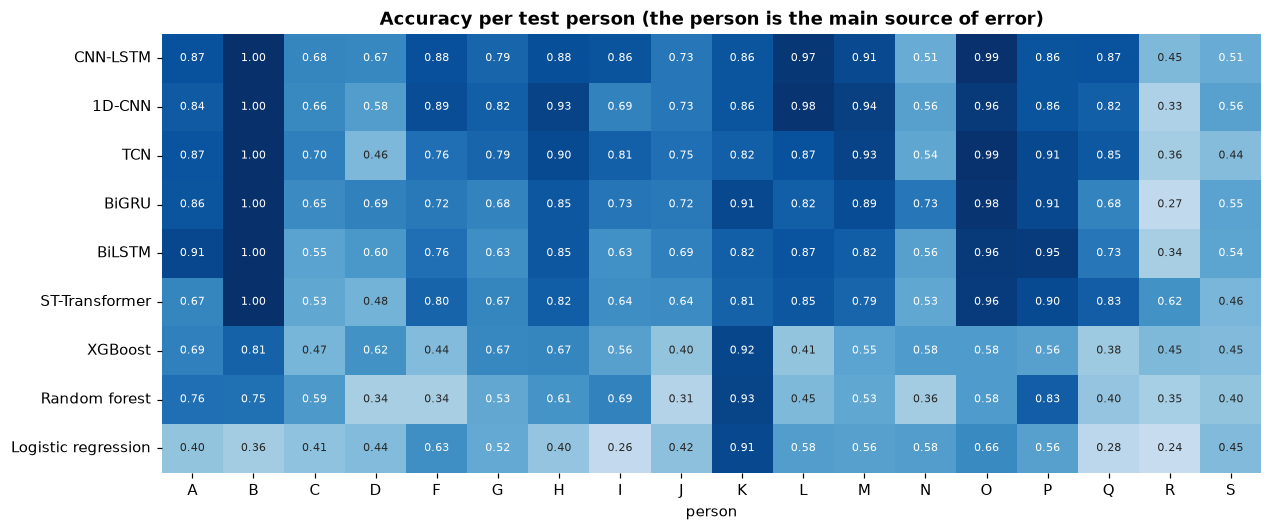

In [9]:
viz.person_accuracy(RUN, list(table["model"]), FIG); plt.show()

## 4. Does α point at the frames that matter?

For every test rep, the 10 % of frames with the highest α are replaced by the rep's mean and the drop of the true-class
probability is measured; the same with 10 % random frames (3 repeats). A meaningful α hurts clearly more when masked.

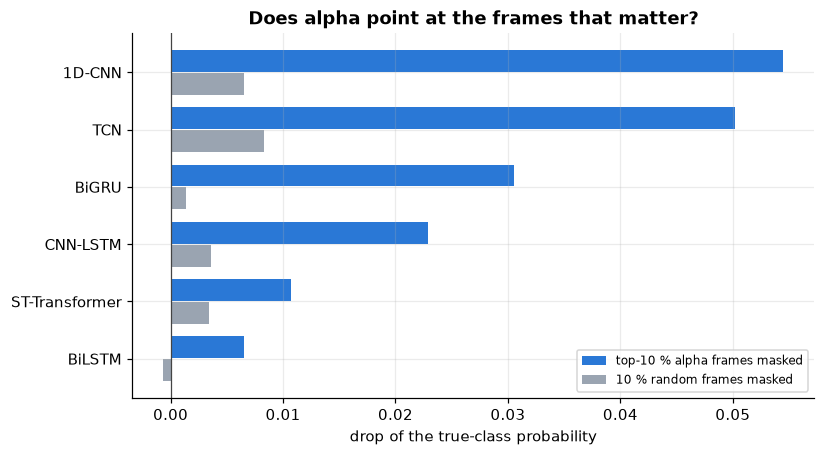

In [10]:
viz.deletion(table[table["alpha_drop"].notna()], FIG); plt.show()

## 5. One report per model (input processing and performance)

## CNN-LSTM  (hybrid)

**Input.** per frame: 151 channels, 64 frames.

**Processing.** 3 Conv1d blocks (kernel 5, 64 channels, LayerNorm, residual) extract local movement, then a 2-layer bidirectional LSTM (32 per direction) relates them over the rep; attention pooling (32) -> alpha; tempo through a small MLP -> classifier.

**Size.** 155,398 trainable parameters. Training: AdamW (lr 0.001, weight decay 0.01), cosine schedule, up to 60 epochs, early stopping on the validation persons (patience 20), label smoothing 0.05, noise augmentation 0.01.

**Common preprocessing.** 3D joints from Pose2Sim -> body frame (lateral / up / forward from the standing posture and the feet), hip-centred, divided by the leg length; reps trimmed to the movement and resampled to 64 frames; z-scored with training-fold statistics.

**Performance (5-fold cross-validation by person x 3 seeds = 15 runs).**

| metric | value |
|---|---|
| macro-F1 per rep | 0.758 ± 0.108 |
| accuracy per rep | 0.775 ± 0.102 |
| macro-F1 per recording (vote) | 0.777 ± 0.123 |
| best / worst run | 0.911 / 0.533 |
| alpha check: drop when the top-10 % alpha frames are masked vs random | 0.023 vs 0.004 |
| median best epoch | 13 |
| training time (15 runs) | 1.5 min |

**F1 per class.**

| class              |    F1 |   reps |
|:-------------------|------:|-------:|
| correct            | 0.580 |    402 |
| insufficient depth | 0.656 |    399 |
| forward lean       | 0.774 |    510 |
| knee valgus        | 0.850 |    432 |
| knee varus         | 0.830 |    489 |
| heel lift          | 0.891 |    567 |

Weakest class: **correct** (F1 0.58). Most frequent confusion: **correct -> insufficient depth** (70 reps).

![confusion](confusion.png)
![learning curves](learning_curves_cnn_lstm.png)
![alpha profile](alpha_profile_cnn_lstm.png)

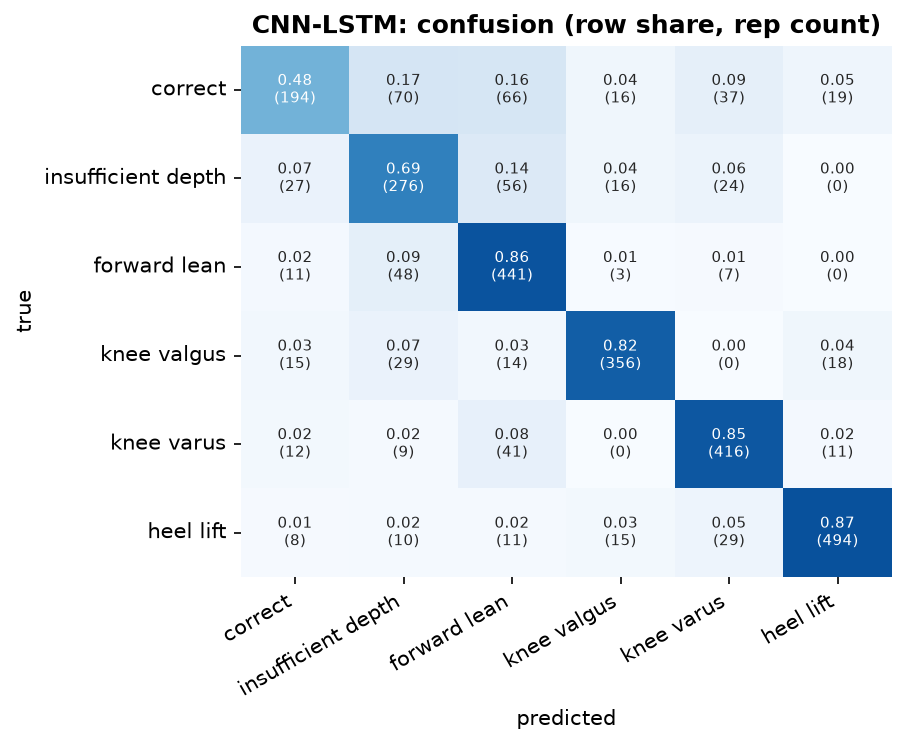

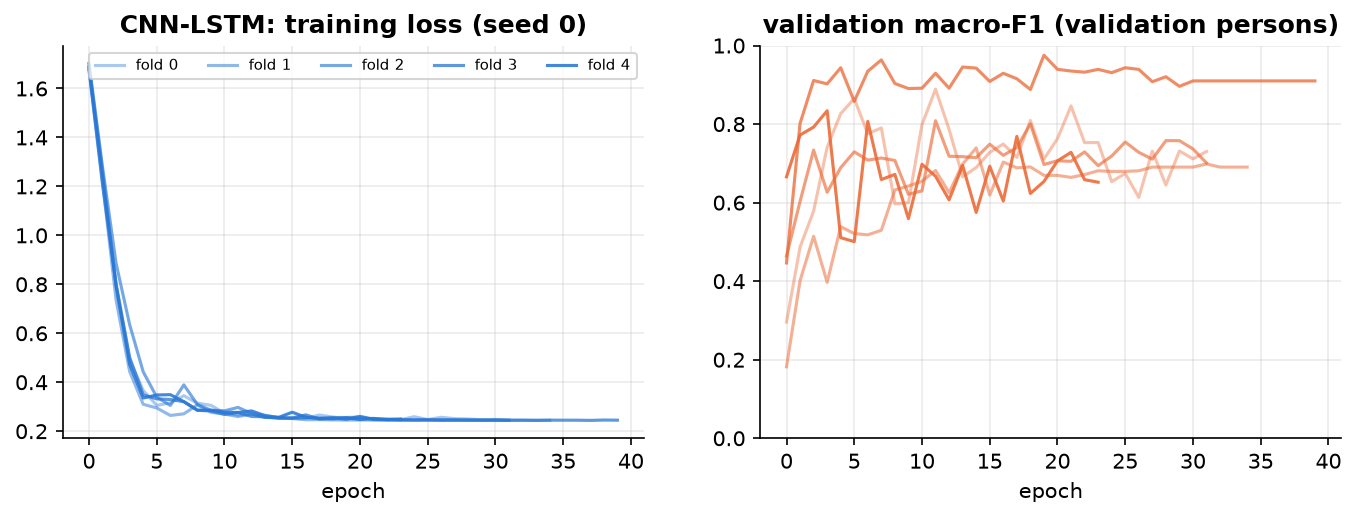

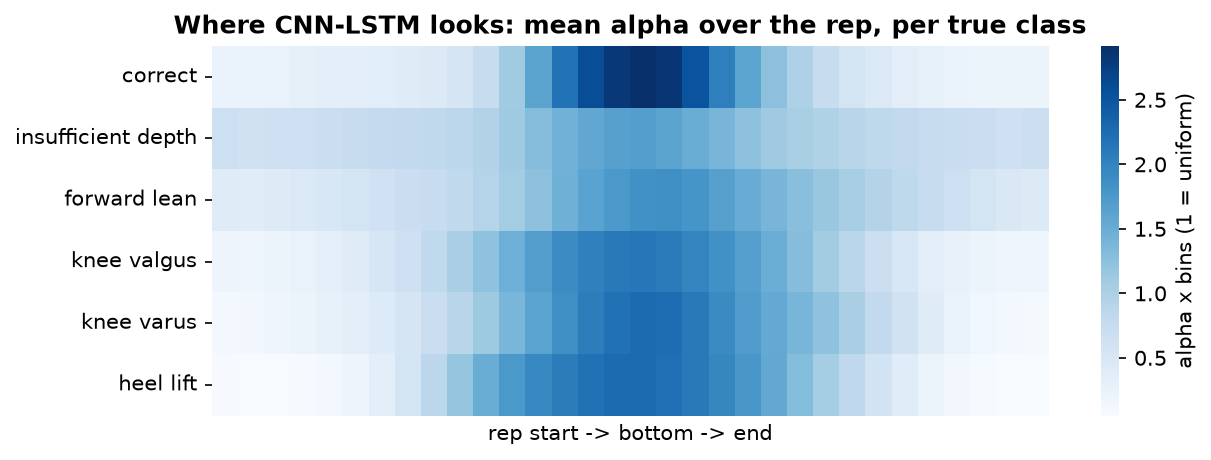

## 1D-CNN  (convolutional)

**Input.** per frame: 22 joints x 6 (position + velocity, body frame) + 19 frame features = 151 channels, 64 frames.

**Processing.** 3 Conv1d layers (kernel 5; 64 -> 128 -> 128 channels; BatchNorm, GELU, dropout): each output sees 13 frames; attention pooling over the 64 frames -> alpha; + 4 tempo numbers -> classifier.

**Size.** 206,598 trainable parameters. Training: AdamW (lr 0.001, weight decay 0.01), cosine schedule, up to 60 epochs, early stopping on the validation persons (patience 20), label smoothing 0.05, noise augmentation 0.01.

**Common preprocessing.** 3D joints from Pose2Sim -> body frame (lateral / up / forward from the standing posture and the feet), hip-centred, divided by the leg length; reps trimmed to the movement and resampled to 64 frames; z-scored with training-fold statistics.

**Performance (5-fold cross-validation by person x 3 seeds = 15 runs).**

| metric | value |
|---|---|
| macro-F1 per rep | 0.747 ± 0.089 |
| accuracy per rep | 0.762 ± 0.091 |
| macro-F1 per recording (vote) | 0.763 ± 0.112 |
| best / worst run | 0.874 / 0.540 |
| alpha check: drop when the top-10 % alpha frames are masked vs random | 0.054 vs 0.006 |
| median best epoch | 10 |
| training time (15 runs) | 1.1 min |

**F1 per class.**

| class              |    F1 |   reps |
|:-------------------|------:|-------:|
| correct            | 0.589 |    402 |
| insufficient depth | 0.609 |    399 |
| forward lean       | 0.828 |    510 |
| knee valgus        | 0.846 |    432 |
| knee varus         | 0.789 |    489 |
| heel lift          | 0.847 |    567 |

Weakest class: **correct** (F1 0.59). Most frequent confusion: **correct -> insufficient depth** (66 reps).

![confusion](confusion.png)
![learning curves](learning_curves_cnn1d.png)
![alpha profile](alpha_profile_cnn1d.png)

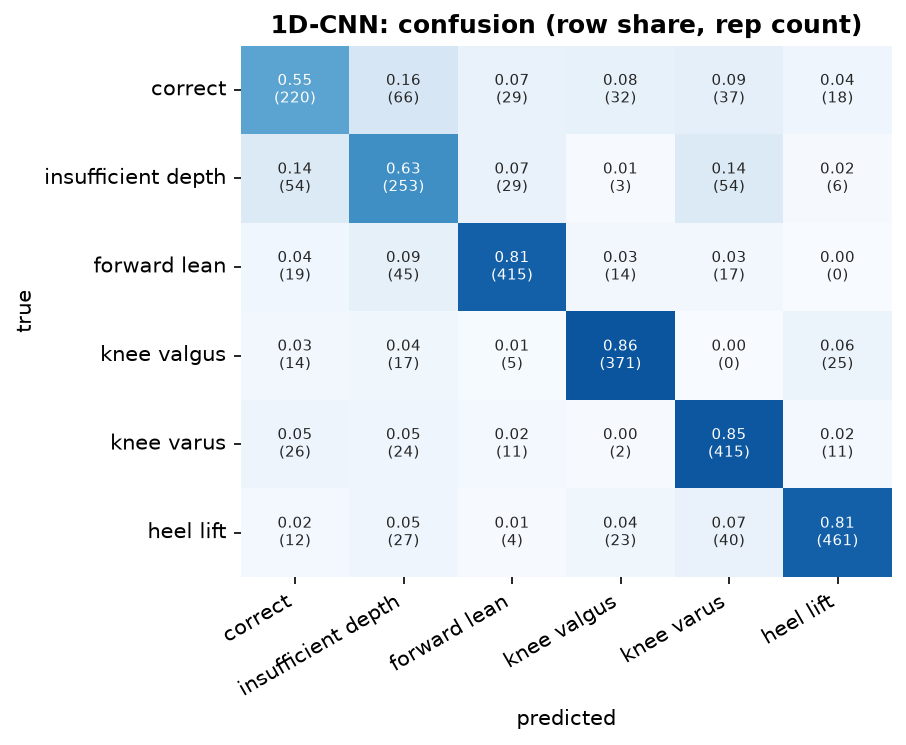

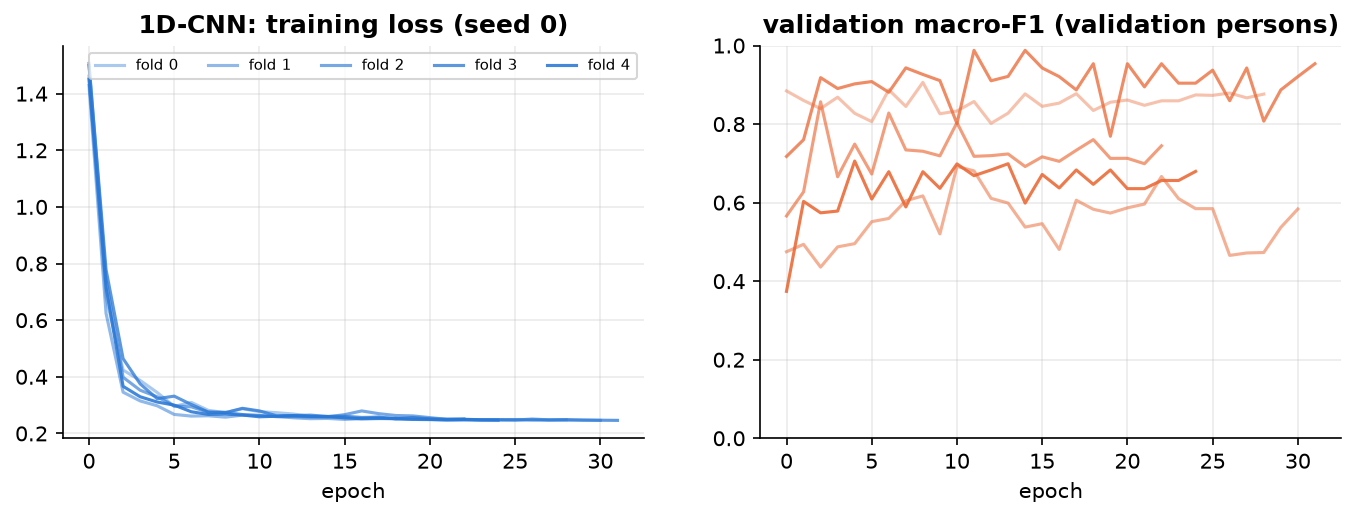

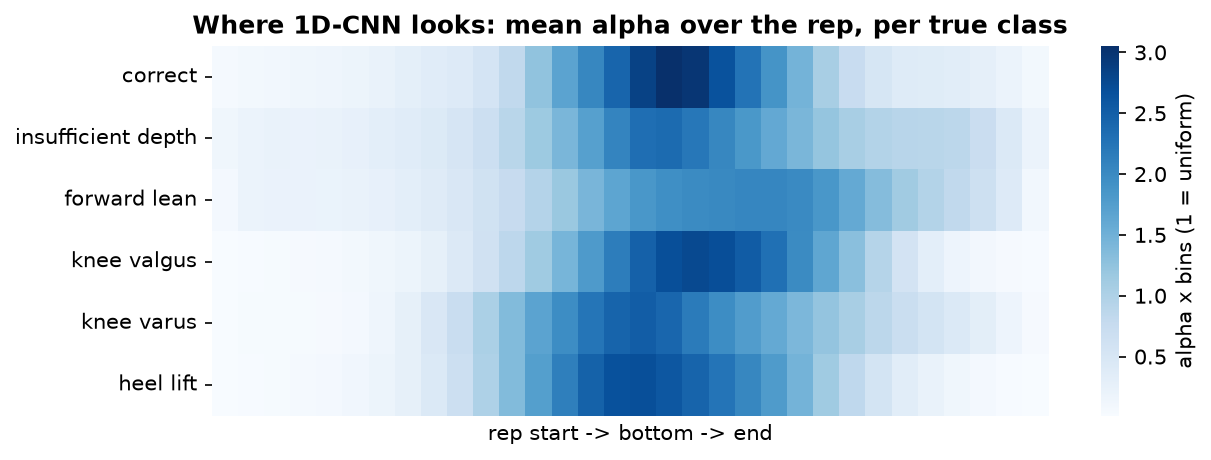

## TCN  (convolutional)

**Input.** per frame: 151 channels, 64 frames.

**Processing.** input projection to 64 channels, 4 residual blocks of two dilated Conv1d (kernel 3, dilation 1, 2, 4, 8; non-causal): the receptive field covers the whole 64-frame rep; attention pooling -> alpha; + tempo -> classifier.

**Size.** 118,598 trainable parameters. Training: AdamW (lr 0.001, weight decay 0.01), cosine schedule, up to 60 epochs, early stopping on the validation persons (patience 20), label smoothing 0.05, noise augmentation 0.01.

**Common preprocessing.** 3D joints from Pose2Sim -> body frame (lateral / up / forward from the standing posture and the feet), hip-centred, divided by the leg length; reps trimmed to the movement and resampled to 64 frames; z-scored with training-fold statistics.

**Performance (5-fold cross-validation by person x 3 seeds = 15 runs).**

| metric | value |
|---|---|
| macro-F1 per rep | 0.734 ± 0.122 |
| accuracy per rep | 0.750 ± 0.112 |
| macro-F1 per recording (vote) | 0.744 ± 0.145 |
| best / worst run | 0.923 / 0.480 |
| alpha check: drop when the top-10 % alpha frames are masked vs random | 0.050 vs 0.008 |
| median best epoch | 10 |
| training time (15 runs) | 1.5 min |

**F1 per class.**

| class              |    F1 |   reps |
|:-------------------|------:|-------:|
| correct            | 0.578 |    402 |
| insufficient depth | 0.634 |    399 |
| forward lean       | 0.767 |    510 |
| knee valgus        | 0.873 |    432 |
| knee varus         | 0.804 |    489 |
| heel lift          | 0.827 |    567 |

Weakest class: **correct** (F1 0.58). Most frequent confusion: **correct -> insufficient depth** (85 reps).

![confusion](confusion.png)
![learning curves](learning_curves_tcn.png)
![alpha profile](alpha_profile_tcn.png)

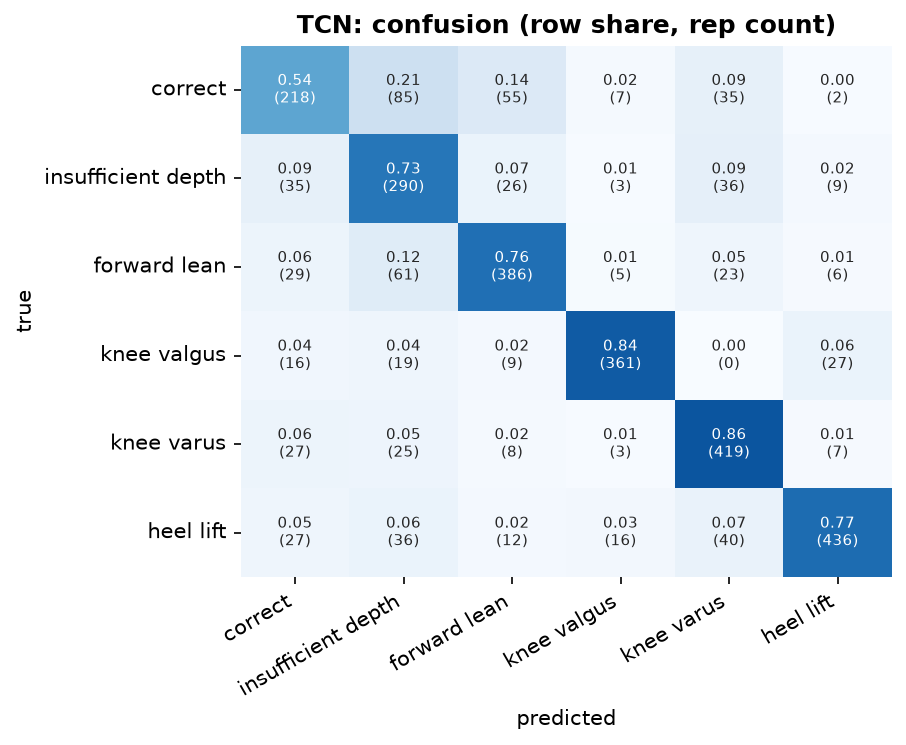

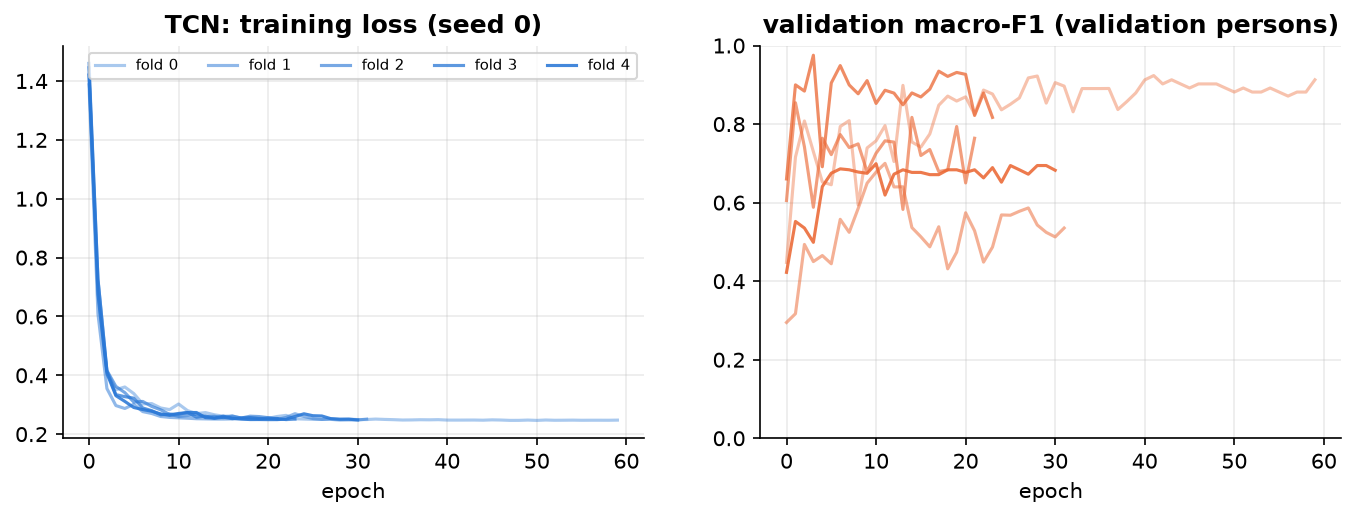

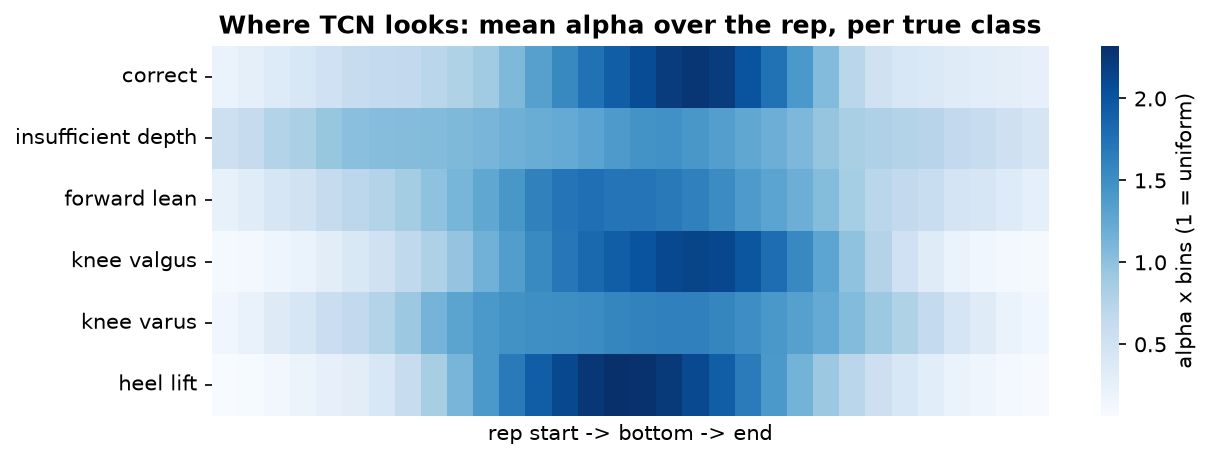

## BiGRU  (recurrent)

**Input.** per frame: 151 channels, 64 frames.

**Processing.** linear projection to 64, 2-layer bidirectional GRU (64 per direction); attention pooling -> alpha; + tempo -> classifier.

**Size.** 168,582 trainable parameters. Training: AdamW (lr 0.001, weight decay 0.01), cosine schedule, up to 60 epochs, early stopping on the validation persons (patience 20), label smoothing 0.05, noise augmentation 0.01.

**Common preprocessing.** 3D joints from Pose2Sim -> body frame (lateral / up / forward from the standing posture and the feet), hip-centred, divided by the leg length; reps trimmed to the movement and resampled to 64 frames; z-scored with training-fold statistics.

**Performance (5-fold cross-validation by person x 3 seeds = 15 runs).**

| metric | value |
|---|---|
| macro-F1 per rep | 0.717 ± 0.100 |
| accuracy per rep | 0.738 ± 0.090 |
| macro-F1 per recording (vote) | 0.754 ± 0.120 |
| best / worst run | 0.878 / 0.493 |
| alpha check: drop when the top-10 % alpha frames are masked vs random | 0.031 vs 0.001 |
| median best epoch | 14 |
| training time (15 runs) | 1.2 min |

**F1 per class.**

| class              |    F1 |   reps |
|:-------------------|------:|-------:|
| correct            | 0.486 |    402 |
| insufficient depth | 0.610 |    399 |
| forward lean       | 0.744 |    510 |
| knee valgus        | 0.872 |    432 |
| knee varus         | 0.785 |    489 |
| heel lift          | 0.862 |    567 |

Weakest class: **correct** (F1 0.49). Most frequent confusion: **correct -> forward lean** (73 reps).

![confusion](confusion.png)
![learning curves](learning_curves_bigru.png)
![alpha profile](alpha_profile_bigru.png)

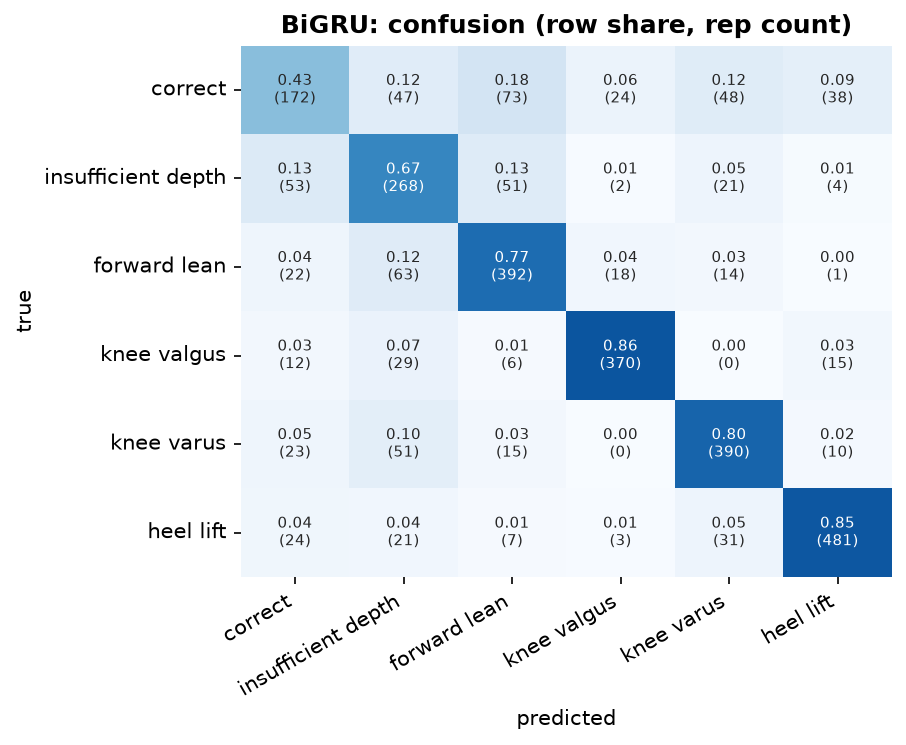

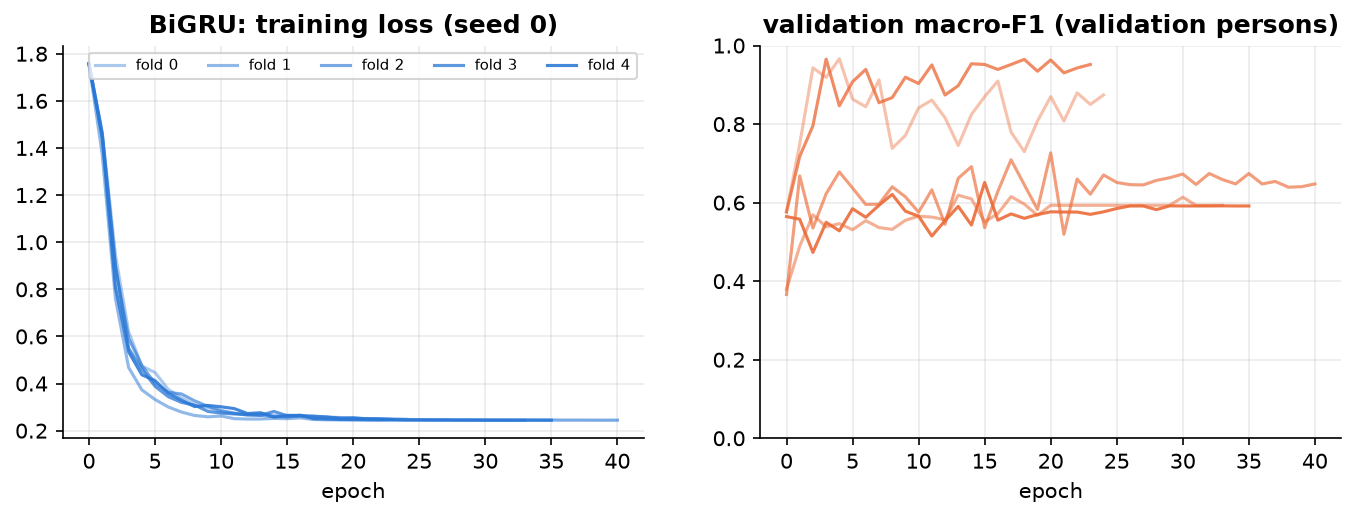

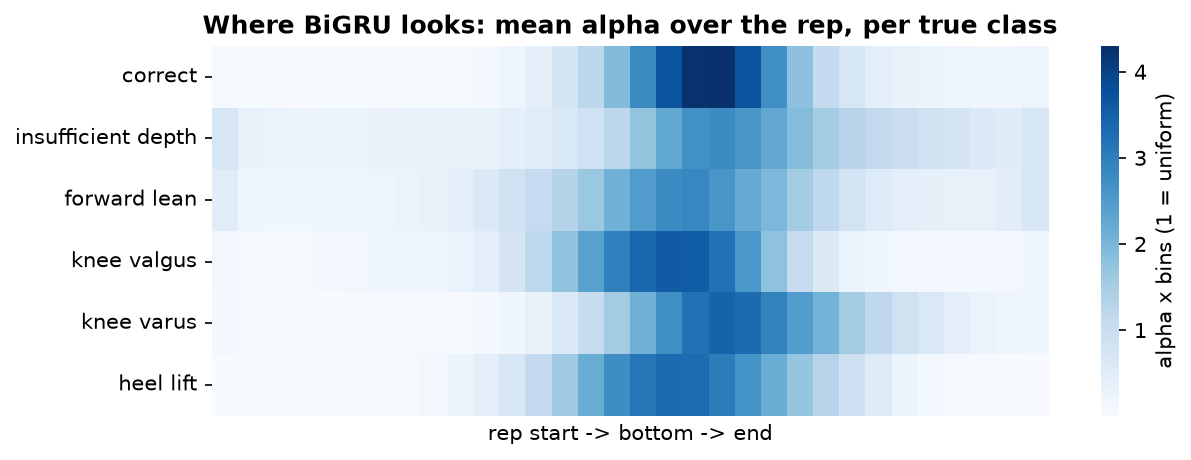

## BiLSTM  (recurrent)

**Input.** per frame: 151 channels (as 1D-CNN), 64 frames.

**Processing.** linear projection to 64, 2-layer bidirectional LSTM (64 per direction): every frame summarises the whole rep in both directions; attention pooling -> alpha; + tempo -> classifier.

**Size.** 210,054 trainable parameters. Training: AdamW (lr 0.001, weight decay 0.01), cosine schedule, up to 60 epochs, early stopping on the validation persons (patience 20), label smoothing 0.05, noise augmentation 0.01.

**Common preprocessing.** 3D joints from Pose2Sim -> body frame (lateral / up / forward from the standing posture and the feet), hip-centred, divided by the leg length; reps trimmed to the movement and resampled to 64 frames; z-scored with training-fold statistics.

**Performance (5-fold cross-validation by person x 3 seeds = 15 runs).**

| metric | value |
|---|---|
| macro-F1 per rep | 0.693 ± 0.078 |
| accuracy per rep | 0.713 ± 0.077 |
| macro-F1 per recording (vote) | 0.737 ± 0.076 |
| best / worst run | 0.807 / 0.518 |
| alpha check: drop when the top-10 % alpha frames are masked vs random | 0.007 vs -0.001 |
| median best epoch | 15 |
| training time (15 runs) | 1.3 min |

**F1 per class.**

| class              |    F1 |   reps |
|:-------------------|------:|-------:|
| correct            | 0.563 |    402 |
| insufficient depth | 0.614 |    399 |
| forward lean       | 0.660 |    510 |
| knee valgus        | 0.782 |    432 |
| knee varus         | 0.762 |    489 |
| heel lift          | 0.851 |    567 |

Weakest class: **correct** (F1 0.56). Most frequent confusion: **forward lean -> insufficient depth** (69 reps).

![confusion](confusion.png)
![learning curves](learning_curves_bilstm.png)
![alpha profile](alpha_profile_bilstm.png)

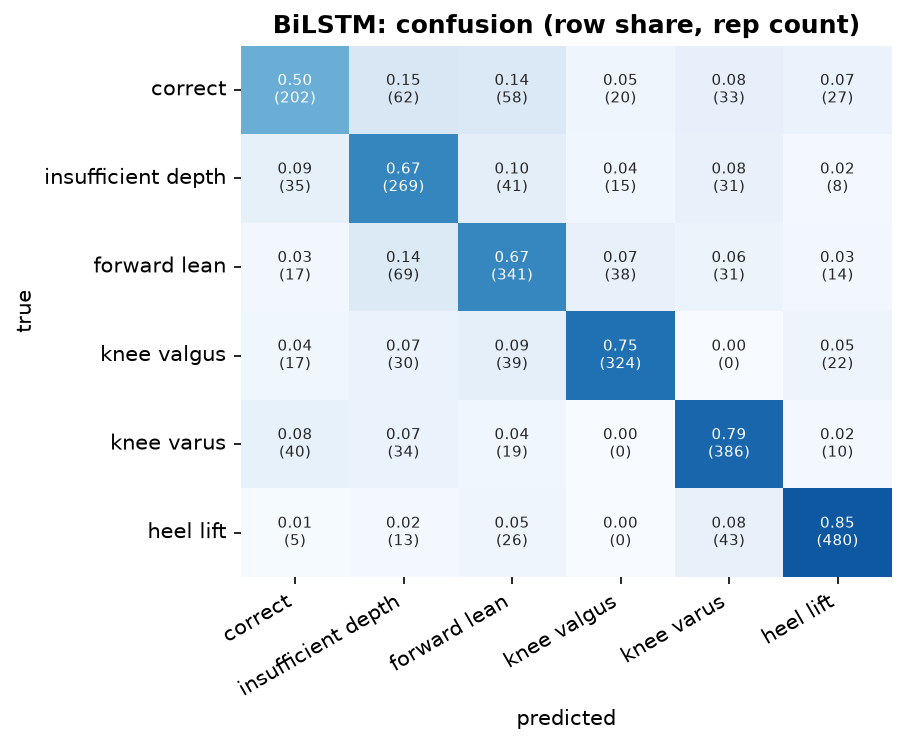

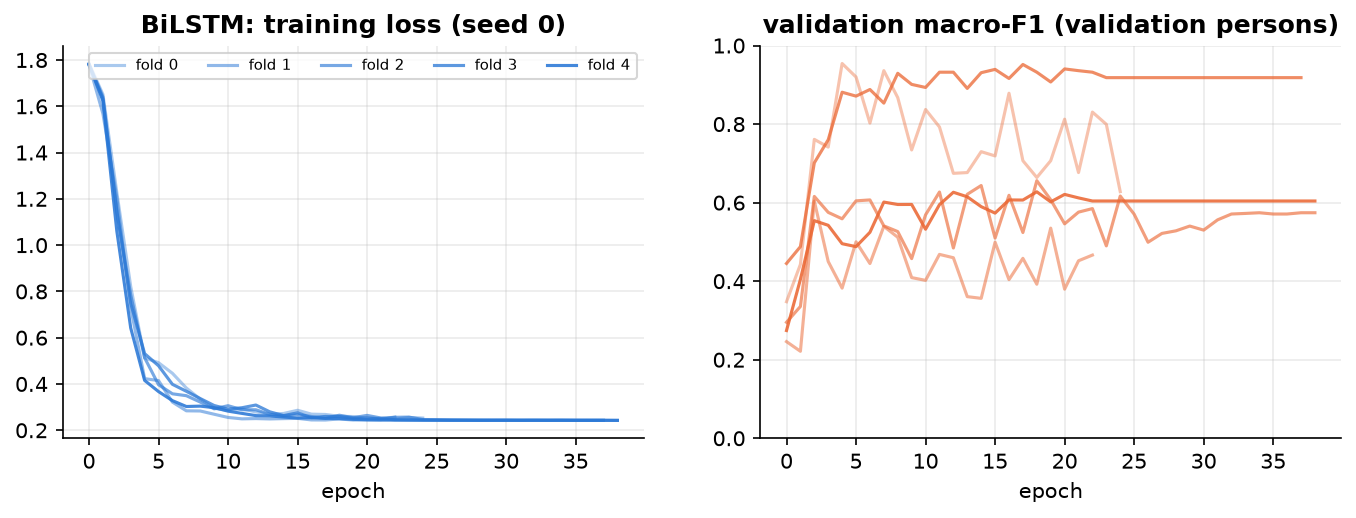

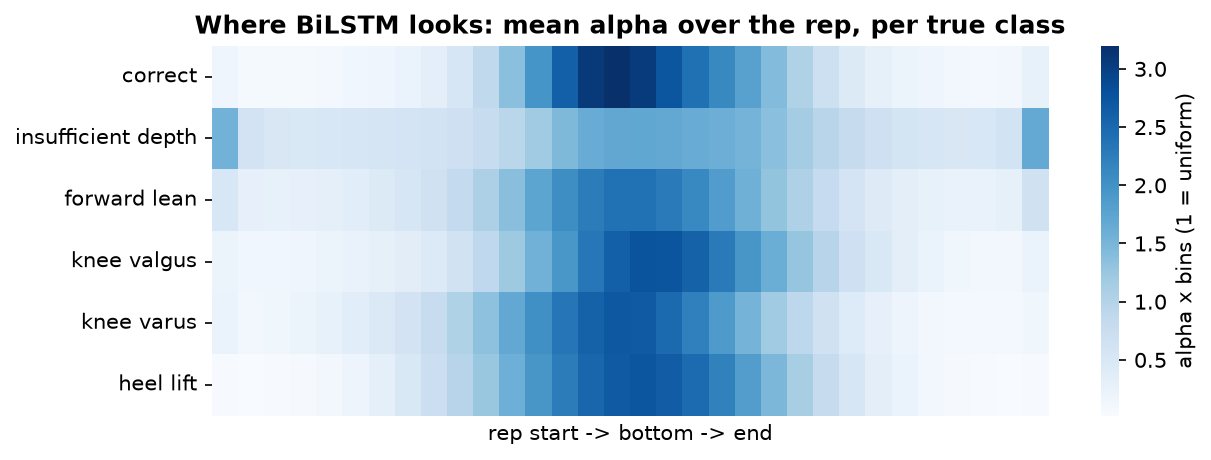

## ST-Transformer  (attention)

**Input.** per frame: 22 joint tokens (6 values each) + 1 frame token (19 features) = 23 tokens, 64 frames.

**Processing.** tokens embedded to 64 + learned joint and time tags; 4 blocks of [spatial self-attention over the 23 tokens of a frame -> temporal self-attention over the 64 frames of each token -> MLP 64-256-64]; the 64 frame tokens -> attention pooling (32) -> alpha; tempo MLP -> classifier.

**Size.** 289,670 trainable parameters. Training: AdamW (lr 0.001, weight decay 0.01), cosine schedule, up to 60 epochs, early stopping on the validation persons (patience 20), label smoothing 0.05, noise augmentation 0.01.

**Common preprocessing.** 3D joints from Pose2Sim -> body frame (lateral / up / forward from the standing posture and the feet), hip-centred, divided by the leg length; reps trimmed to the movement and resampled to 64 frames; z-scored with training-fold statistics.

**Performance (5-fold cross-validation by person x 3 seeds = 15 runs).**

| metric | value |
|---|---|
| macro-F1 per rep | 0.677 ± 0.093 |
| accuracy per rep | 0.706 ± 0.086 |
| macro-F1 per recording (vote) | 0.689 ± 0.121 |
| best / worst run | 0.861 / 0.511 |
| alpha check: drop when the top-10 % alpha frames are masked vs random | 0.011 vs 0.003 |
| median best epoch | 6 |
| training time (15 runs) | 56.4 min |

**F1 per class.**

| class              |    F1 |   reps |
|:-------------------|------:|-------:|
| correct            | 0.482 |    402 |
| insufficient depth | 0.608 |    399 |
| forward lean       | 0.707 |    510 |
| knee valgus        | 0.807 |    432 |
| knee varus         | 0.737 |    489 |
| heel lift          | 0.809 |    567 |

Weakest class: **correct** (F1 0.48). Most frequent confusion: **correct -> insufficient depth** (60 reps).

![confusion](confusion.png)
![learning curves](learning_curves_st_transformer.png)
![alpha profile](alpha_profile_st_transformer.png)

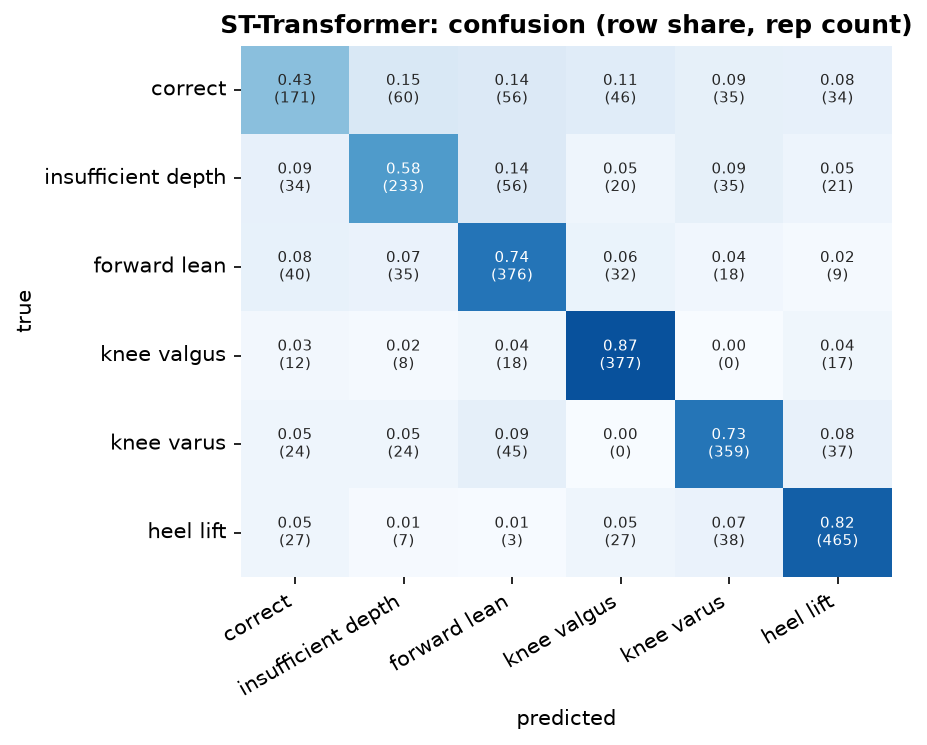

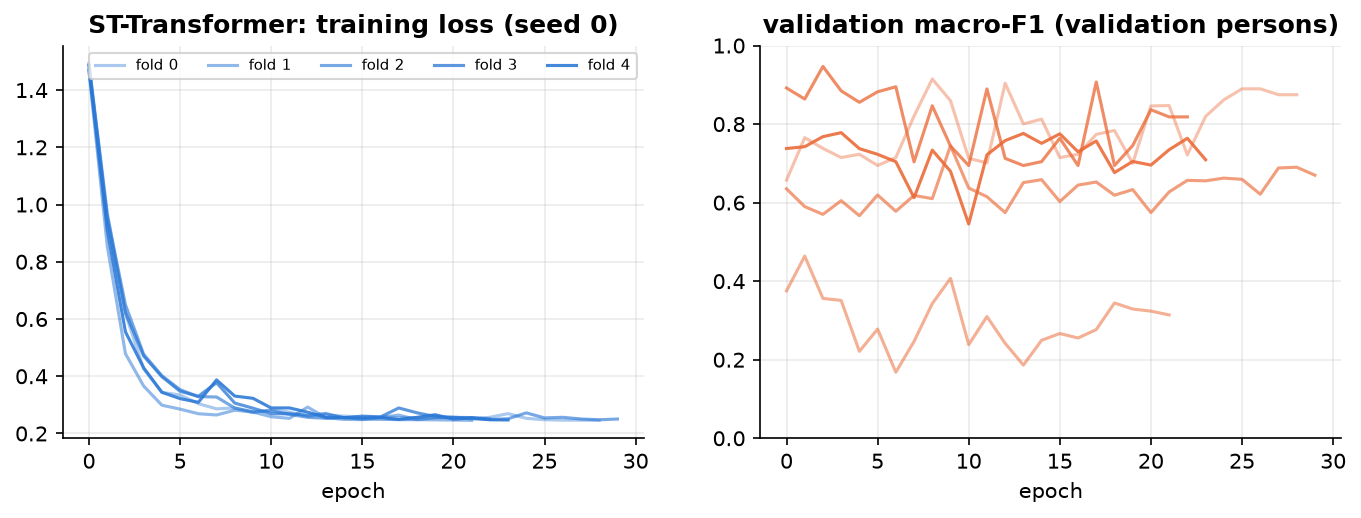

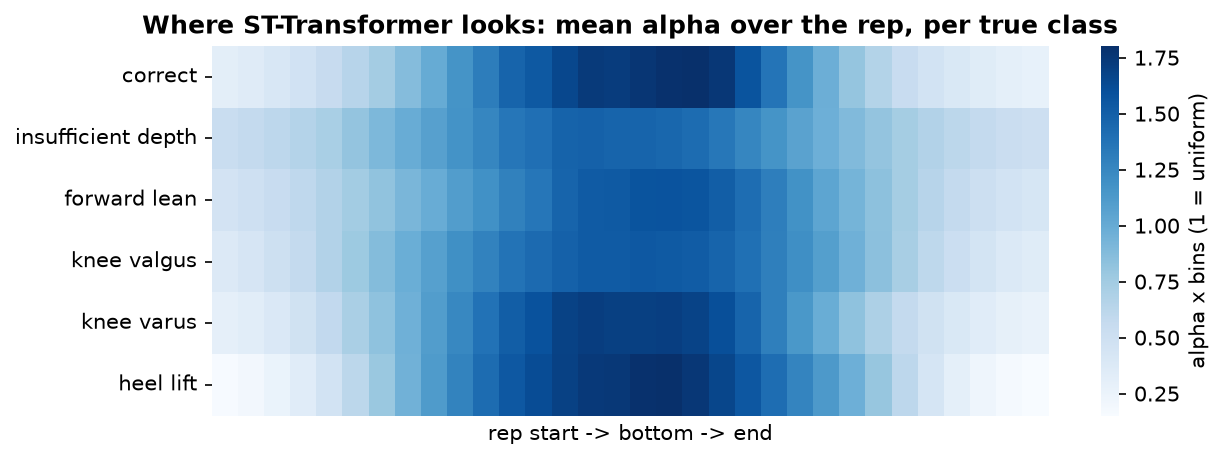

## XGBoost  (classical baseline)

**Input.** summary row (46) + tempo (4) = 50 values per rep.

**Processing.** median imputation, 300 gradient-boosted trees, depth 4, learning rate 0.1, row / column subsampling 0.9.

**Preprocessing.** The summary row is computed by the Pose2Sim preprocessing pipeline per rep (`rep_features.csv`, statistics of its joint angles); the 4 tempo numbers come from the trimmed rep. No body-frame joints are used.

**Performance (5-fold cross-validation by person x 3 seeds = 15 runs).**

| metric | value |
|---|---|
| macro-F1 per rep | 0.527 ± 0.053 |
| accuracy per rep | 0.546 ± 0.043 |
| macro-F1 per recording (vote) | 0.564 ± 0.088 |
| best / worst run | 0.604 / 0.399 |
| training time (15 runs) | 0.4 min |

**F1 per class.**

| class              |    F1 |   reps |
|:-------------------|------:|-------:|
| correct            | 0.300 |    402 |
| insufficient depth | 0.622 |    399 |
| forward lean       | 0.541 |    510 |
| knee valgus        | 0.605 |    432 |
| knee varus         | 0.467 |    489 |
| heel lift          | 0.682 |    567 |

Weakest class: **correct** (F1 0.30). Most frequent confusion: **forward lean -> knee valgus** (106 reps).

![confusion](confusion.png)

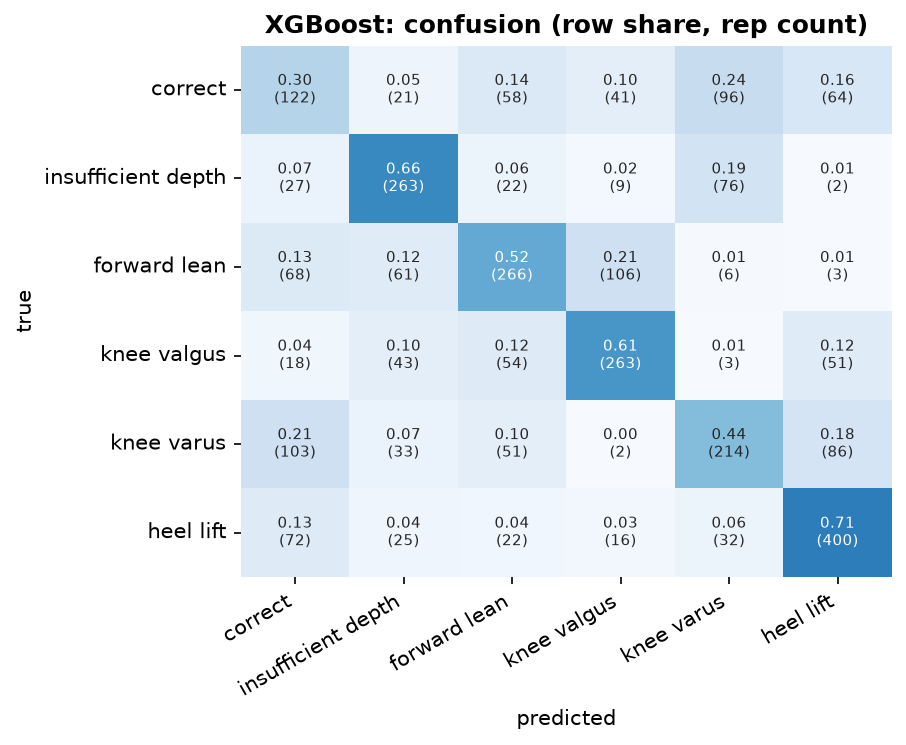

## Random forest  (classical baseline)

**Input.** summary row (46) + tempo (4) = 50 values per rep.

**Processing.** median imputation, 300 decision trees (bootstrap), majority of tree probabilities.

**Preprocessing.** The summary row is computed by the Pose2Sim preprocessing pipeline per rep (`rep_features.csv`, statistics of its joint angles); the 4 tempo numbers come from the trimmed rep. No body-frame joints are used.

**Performance (5-fold cross-validation by person x 3 seeds = 15 runs).**

| metric | value |
|---|---|
| macro-F1 per rep | 0.508 ± 0.052 |
| accuracy per rep | 0.529 ± 0.049 |
| macro-F1 per recording (vote) | 0.517 ± 0.067 |
| best / worst run | 0.608 / 0.427 |
| training time (15 runs) | 0.2 min |

**F1 per class.**

| class              |    F1 |   reps |
|:-------------------|------:|-------:|
| correct            | 0.256 |    402 |
| insufficient depth | 0.593 |    399 |
| forward lean       | 0.601 |    510 |
| knee valgus        | 0.501 |    432 |
| knee varus         | 0.502 |    489 |
| heel lift          | 0.647 |    567 |

Weakest class: **correct** (F1 0.26). Most frequent confusion: **knee varus -> correct** (127 reps).

![confusion](confusion.png)

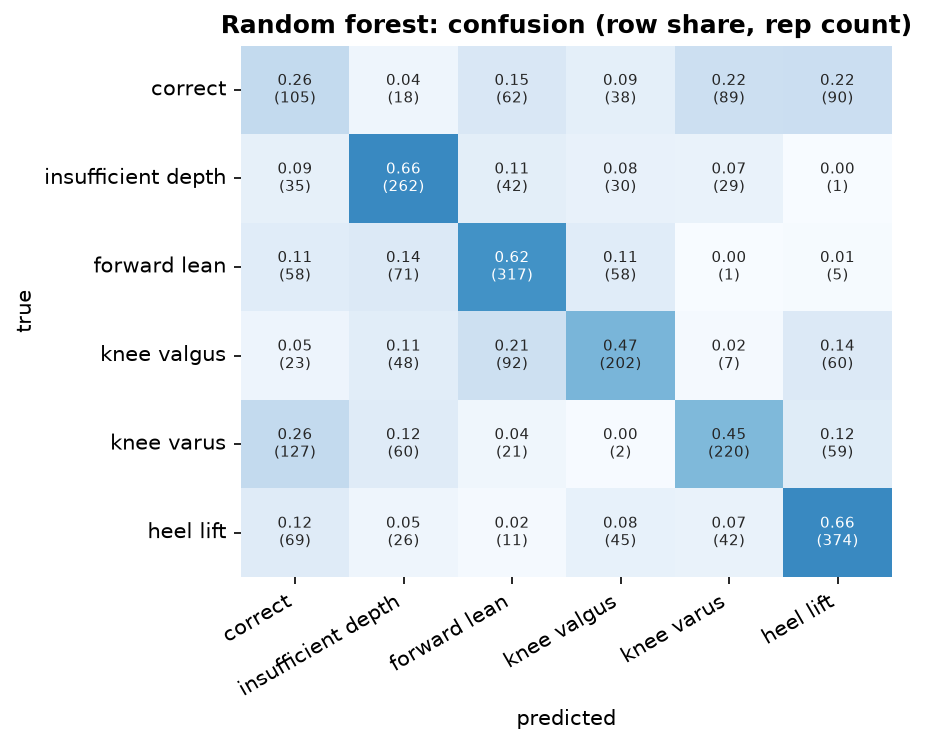

## Logistic regression  (classical baseline)

**Input.** summary row: 46 statistics per rep from rep_features.csv (min / max / at-bottom of each pipeline angle) + 4 tempo numbers = 50 values.

**Processing.** median imputation of missing values, z-score, multinomial logistic regression (L2, C = 1); sample weights: every recording counts equally.

**Preprocessing.** The summary row is computed by the Pose2Sim preprocessing pipeline per rep (`rep_features.csv`, statistics of its joint angles); the 4 tempo numbers come from the trimmed rep. No body-frame joints are used.

**Performance (5-fold cross-validation by person x 3 seeds = 15 runs).**

| metric | value |
|---|---|
| macro-F1 per rep | 0.460 ± 0.078 |
| accuracy per rep | 0.478 ± 0.076 |
| macro-F1 per recording (vote) | 0.470 ± 0.130 |
| best / worst run | 0.580 / 0.279 |
| training time (15 runs) | 0.0 min |

**F1 per class.**

| class              |    F1 |   reps |
|:-------------------|------:|-------:|
| correct            | 0.312 |    402 |
| insufficient depth | 0.493 |    399 |
| forward lean       | 0.501 |    510 |
| knee valgus        | 0.513 |    432 |
| knee varus         | 0.402 |    489 |
| heel lift          | 0.598 |    567 |

Weakest class: **correct** (F1 0.31). Most frequent confusion: **heel lift -> knee varus** (96 reps).

![confusion](confusion.png)

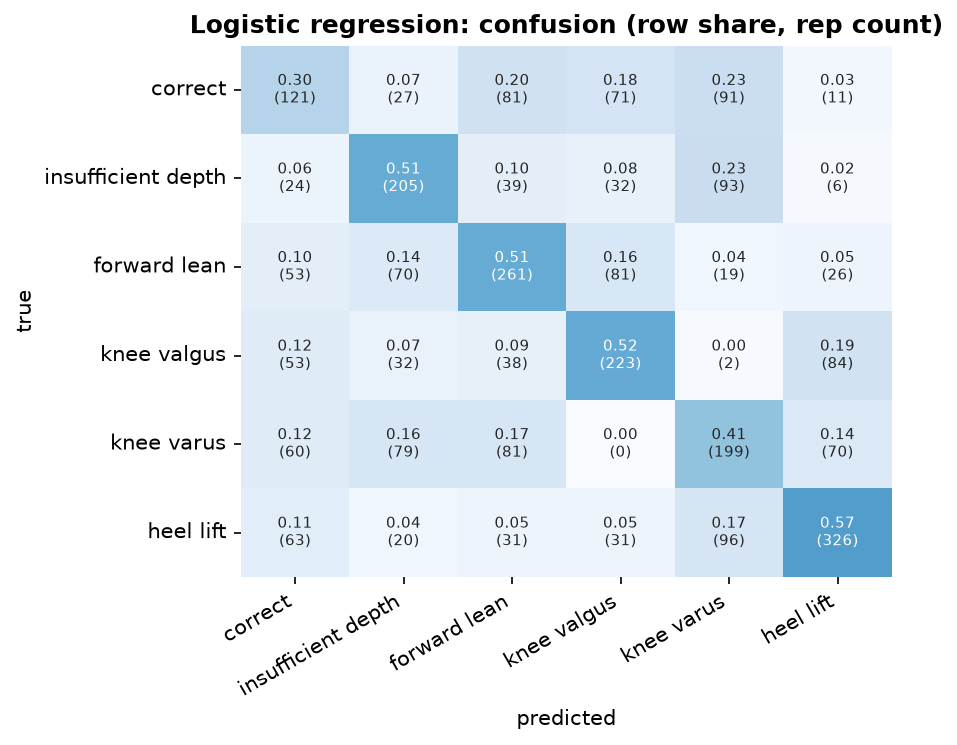

In [11]:
for m in table["model"]:
    display(Markdown(model_report(RUN, m, ds, cfg, REP)))
    for f in ["confusion.png", f"learning_curves_{m}.png", f"alpha_profile_{m}.png"]:
        if (REP / m / f).exists():
            display(Image(filename=str(REP / m / f), width=640))

## 6. Choosing the best model

**Rule** (fixed before looking at the numbers):
1. Candidates: neural models whose α passes the check (masking the α frames drops the true-class probability ≥ 2 × more than random frames).
2. Highest mean macro-F1 over the 15 runs; models within one standard deviation of it count as tied.
3. Among tied models: higher recording-level macro-F1, then fewer parameters (the product runs on a CPU).

The paired test compares the chosen model with every other model on the same 15 runs (p < 0.05 = a real difference).

In [12]:
neural = table[table["group"] == "neural"].reset_index(drop=True)
best, rule = select_best(neural)
display(rule[["name", "macro_f1", "macro_f1_std", "rec_macro_f1", "alpha_drop", "random_drop", "alpha_ok", "tied_with_best", "params", "chosen"]])
fb = fold_scores(RUN, best)
paired = pd.DataFrame([{"compared with": r["name"], **paired_test(fb, fold_scores(RUN, r["model"]))} for _, r in table.iterrows() if r["model"] != best])
paired.to_csv(OUT / "paired_tests_best_vs_others.csv", index=False); display(paired)

,name,macro_f1,macro_f1_std,rec_macro_f1,alpha_drop,random_drop,alpha_ok,tied_with_best,params,chosen
0,CNN-LSTM,0.758,0.108,0.777,0.023,3.591e-03,True,True,155398.0,True
1,1D-CNN,0.747,0.089,0.763,0.054,6.497e-03,True,True,206598.0,False
2,TCN,0.734,0.122,0.744,0.050,8.308e-03,True,True,118598.0,False
3,BiGRU,0.717,0.100,0.754,0.031,1.326e-03,True,True,168582.0,False
4,BiLSTM,0.693,0.078,0.737,0.007,-6.431e-04,True,True,210054.0,False
5,ST-Transformer,0.677,0.093,0.689,0.011,3.422e-03,True,True,289670.0,False


,compared with,mean_diff,wins,losses,p_value
0,1D-CNN,0.011,6,9,5.995e-01
1,TCN,0.023,9,6,4.887e-01
2,BiGRU,0.041,10,5,2.293e-01
3,BiLSTM,0.065,12,3,4.272e-03
4,ST-Transformer,0.081,12,3,8.362e-03
5,XGBoost,0.231,14,1,1.831e-04
6,Random forest,0.250,15,0,6.104e-05
7,Logistic regression,0.298,15,0,6.104e-05


In [13]:
b = table.set_index("model").loc[best]
info = dict(model=best, name=nice(best), macro_f1=b["macro_f1"], macro_f1_std=b["macro_f1_std"], rec_macro_f1=b["rec_macro_f1"],
            alpha_drop=b["alpha_drop"], random_drop=b["random_drop"], params=int(b["params"]), median_best_epoch=b["median_best_epoch"],
            tied=list(rule.loc[rule["tied_with_best"], "model"]), minutes_per_15_runs=b["minutes"])
write_json(OUT / "best_model.json", info)
cls = table[table["group"] == "classical baseline"].iloc[0]
txt = (f"**Chosen model: {info['name']}**: macro-F1 {info['macro_f1']:.3f} ± {info['macro_f1_std']:.3f}, recording level "
       f"{info['rec_macro_f1']:.3f}, α check {info['alpha_drop']:.3f} vs random {info['random_drop']:.3f}, {info['params']:,} parameters. "
       f"Tied within one standard deviation: {', '.join(nice(m) for m in info['tied'])}. Best classical baseline: {cls['name']} ({cls['macro_f1']:.3f}).")
(OUT / "summary.md").write_text(txt, encoding="utf-8"); display(Markdown(txt))

**Chosen model: CNN-LSTM**: macro-F1 0.758 ± 0.108, recording level 0.777, α check 0.023 vs random 0.004, 155,398 parameters. Tied within one standard deviation: CNN-LSTM, 1D-CNN, TCN, BiGRU, BiLSTM, ST-Transformer. Best classical baseline: XGBoost (0.527).